<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/geo4bolivia_quickstart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Load, link and build Bolivian indicators with `geo4bolivia`

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

This notebook is a hands-on tour of the observatory's data for Bolivia's 339 municipalities:

1. **Load data without the package**: every file is a plain URL
2. **Load data with the package** `geo4bolivia`
3. **Move data across scales**: municipalities, provinces, departments and the country
4. **Link your own table** to the observatory's units, by name or by INE code
5. **Build a new indicator from a raster**
6. **Interpolate to a grid**, then **save** your dataset in the observatory's format

The companion notebooks ([list](https://github.com/quarcs-lab/geo4bolivia/tree/main/notebooks)) analyse the same data: exploratory spatial analysis, inequality, geographically weighted regression, and poverty prediction from satellite embeddings.

## 0. Setup

In Google Colab the next cell installs the package (a few seconds: Colab already has its dependencies). Locally, `uv sync` has installed it already.

In [1]:
import importlib.util

if importlib.util.find_spec("geo4bolivia") is None:
    !pip install -q "geo4bolivia[raster]" mapclassify

In [2]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

## 1. Load data without the package

Every published file is a plain URL, so pandas, geopandas, R, Stata or Excel can read it directly. Three kinds of files matter:

- **`data/<scale>/<dataset>.csv`**: the indicators, as a panel with one row per unit (`geo_id`) and year
- **`geo/units.csv`**: names, parent units and the codes other sources use (INE, DS4Bolivia, GADM)
- **`geo/boundaries/<scale>.geojson`**: polygons, keyed by the same `geo_id`

In [3]:
BASE = "https://raw.githubusercontent.com/quarcs-lab/geo4bolivia/main/"

ntl = pd.read_csv(BASE + "data/municipality/ntl.csv")              # 339 municipalities x 9 years
units = pd.read_csv(BASE + "geo/units.csv", dtype={"ine_code": str})   # 461 units at 4 scales
municipalities = gpd.read_file(BASE + "geo/boundaries/municipality.geojson")

ntl.head()

,geo_id,year,asdf_id,ln_NTLpc,ln_t400NTLpc
0,BO-01-01-01,2012,174,11.136693,11.048312
1,BO-01-01-01,2013,174,11.400161,11.310169
2,BO-01-01-01,2014,174,11.328924,11.572208
3,BO-01-01-01,2015,174,11.476696,11.834868
4,BO-01-01-01,2016,174,11.913466,12.097983


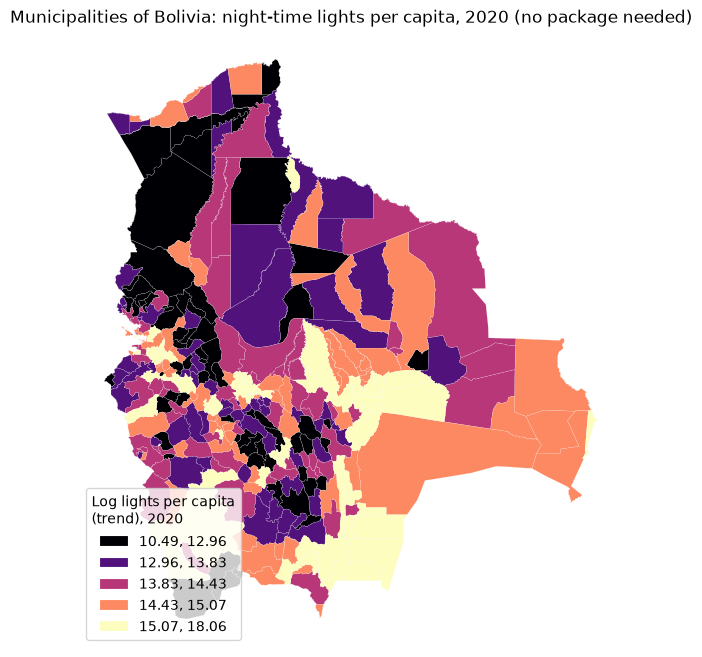

In [4]:
# Names come from geo/units.csv; every row also carries the ids of the units it lies in
names = units.loc[units["scale"] == "municipality", ["geo_id", "department_id"]]
ntl_2020 = municipalities.merge(ntl[ntl["year"] == 2020], on="geo_id").merge(names, on="geo_id")

ax = ntl_2020.plot(column="ln_t400NTLpc", cmap="magma", scheme="quantiles", k=5, legend=True,
                   legend_kwds={"title": "Log lights per capita\n(trend), 2020", "loc": "lower left"},
                   edgecolor="white", linewidth=0.1, figsize=(8, 8))
ax.set_axis_off()
ax.set_title("Municipalities of Bolivia: night-time lights per capita, 2020 (no package needed)");

## 2. Load data with the package

The package does the same in one line, and more: it lists the datasets, describes their variables, filters years and variables, reshapes, and attaches boundaries.

In [5]:
import geo4bolivia as geo

geo.datasets()

,dataset,scale,title,first_year,last_year,variables,csv,parquet
0,pop,municipality,Population,2001,2020,1,data/municipality/pop.csv,data/municipality/pop.parquet
1,ntl,municipality,Night-time lights per capita,2012,2020,2,data/municipality/ntl.csv,data/municipality/ntl.parquet
2,sdg,municipality,SDG indicators (Municipal Atlas of the SDGs 2020),2010,2020,64,data/municipality/sdg.csv,data/municipality/sdg.parquet
3,emb,municipality,Satellite embeddings 2017 (area-weighted),2017,2017,64,data/municipality/emb.csv,data/municipality/emb.parquet
4,embpw,municipality,Satellite embeddings 2017 (population-weighted),2017,2017,64,data/municipality/embpw.csv,data/municipality/embpw.parquet


In [6]:
geo.dictionary("sdg").head(8)      # every variable: description, unit, aggregation rule, source

,variable,description,unit,role,aggregation,source
0,geo_id,Municipality geo ID,,id,,
1,year,Year,,time,,
2,mun_id,"INE municipality code (DDPPMM, without the lea...",,source_key,,INE via DS4Bolivia
3,population_2020,Population,people,variable,sum,Municipal Atlas of the SDGs in Bolivia 2020
4,urbano_2012,Urbanization rate,% of population,variable,none,Municipal Atlas of the SDGs in Bolivia 2020
5,sdg1_1_eepr,Extreme energy poverty rate,% of houses,variable,none,Municipal Atlas of the SDGs in Bolivia 2020
6,sdg1_1_ubn,Unsatisfied basic needs,% of population,variable,none,Municipal Atlas of the SDGs in Bolivia 2020
7,sdg1_2_mpi,Multidimensional poverty index,index,variable,none,Municipal Atlas of the SDGs in Bolivia 2020


The SDG indicators come from the Municipal Atlas of the SDGs 2020, and each was measured in its own year (poverty in the 2012 census, infant mortality in 2016, ...). The `sdg` dataset stores each indicator **at its reference year**, so load one indicator with its year:

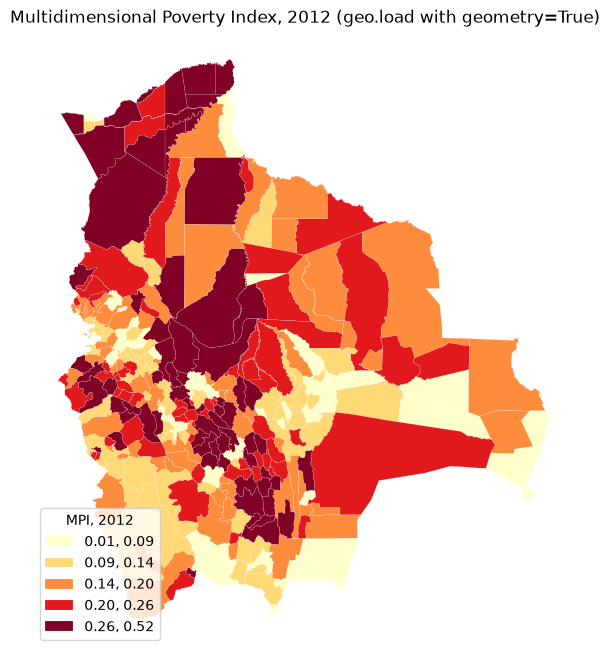

In [7]:
gdf = geo.load("sdg", variables="sdg1_2_mpi", years=2012, geometry=True)   # a GeoDataFrame, ready to map
ax = gdf.plot(column="sdg1_2_mpi", cmap="YlOrRd", scheme="quantiles", k=5, legend=True,
              legend_kwds={"title": "MPI, 2012", "loc": "lower left"}, edgecolor="white", linewidth=0.1, figsize=(8, 8))
ax.set_axis_off()
ax.set_title("Multidimensional Poverty Index, 2012 (geo.load with geometry=True)");

In [8]:
# A window of years and a variable; or one row per unit with one column per year
lights = geo.load("ntl", years=(2012, 2016), variables=["ln_NTLpc"])
wide = geo.load("pop", wide="pop")
lights.head(3), wide.iloc[:3, :6]

(        geo_id  year   ln_NTLpc
 0  BO-01-01-01  2012  11.136693
 1  BO-01-01-01  2013  11.400161
 2  BO-01-01-01  2014  11.328924,
         geo_id    pop2001    pop2002    pop2003    pop2004    pop2005
 0  BO-01-01-01  11718.431  11621.795  11556.641  11482.748  11421.702
 1  BO-01-01-02  15737.872  15611.149  15519.731  15289.985  15159.410
 2  BO-01-02-01  12278.948  12186.130  12079.739  11962.021  11882.662)

In [9]:
# names, parents, and the codes each source uses: GADM (gid), INE (ine_code, mun_id), DS4Bolivia (asdf_id)
geo.units("municipality").head(3)

,geo_id,scale,name,parent_id,country_id,department_id,province_id,municipality_id,gid,ine_code,asdf_id,mun_id,name_gadm,area_km2
0,BO-01-01-01,municipality,Azurduy,BO-01-01,BO,BO-01,BO-01-01,BO-01-01-01,BOL.1.1.1_2,010201,174,10201,Azurduy,1728.99
1,BO-01-01-02,municipality,Tarvita,BO-01-01,BO,BO-01,BO-01-01,BO-01-01-02,BOL.1.1.2_2,010202,186,10202,Tarvita,1354.43
2,BO-01-02-01,municipality,Villa Serrano,BO-01-02,BO,BO-01,BO-01-02,BO-01-02-01,BOL.1.2.1_2,010801,246,10801,VillaSerrano,1730.77


## 3. Move data across scales

Each scale nests in the coarser ones, and each variable's metadata says how it may be aggregated: `sum` for totals such as population, `none` for logs, rates and indices that need weights.

In [10]:
geo.scales()          # the registry of scales

,label,kind,parent,children,id_pattern,example,status
scale,,,,,,,
country,Country,admin,None,None,^BO$,BO,active
department,Department,admin,country,None,^BO-\d{2}$,BO-04,active
province,Province,admin,department,None,^BO-\d{2}-\d{2}$,BO-04-17,active
municipality,"Municipality (339, GADM 4.1)",admin,province,None,^BO-\d{2}-\d{2}-\d{2}$,BO-04-17-04,active
municipality_ine,Municipality (current INE map),custom,None,None,^BO-INE-\d{6}$,BO-INE-020101,planned
grid10k,10 km grid cell,grid,None,None,^BO-G10K-r\d{3}c\d{3}$,BO-G10K-r012c034,planned


In [11]:
pop = geo.load("pop", years=2020)
by_department = geo.aggregate(pop, to="department", dataset="pop")    # 339 municipalities -> 9 departments
by_department.merge(geo.units("department")[["geo_id", "name"]], on="geo_id").sort_values("pop", ascending=False)

,geo_id,year,pop,n_units,name
7,BO-08,2020,3.287980e+06,56,Santa Cruz
3,BO-04,2020,3.099358e+06,87,La Paz
1,BO-02,2020,2.056889e+06,47,Cochabamba
6,BO-07,2020,9.423829e+05,40,Potosí
0,BO-01,2020,6.253691e+05,29,Chuquisaca
4,BO-05,2020,5.977664e+05,35,Oruro
8,BO-09,2020,5.856987e+05,11,Tarija
2,BO-03,2020,4.816475e+05,19,Beni
5,BO-06,2020,2.005733e+05,15,Pando


Poverty is a rate, so its departmental value is a **population-weighted** mean. `weights=` brings the population of the same year:

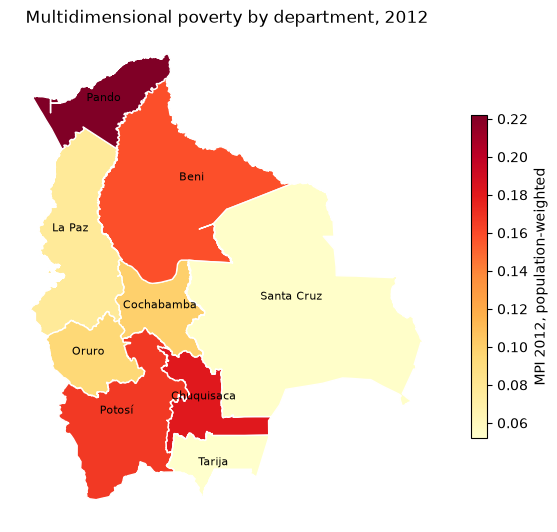

In [12]:
mpi = geo.load("sdg", variables="sdg1_2_mpi", years=2012)
mpi_dep = geo.aggregate(mpi, to="department", rules={"sdg1_2_mpi": "weighted_mean:pop"}, weights=geo.load("pop"))
mpi_dep = geo.boundaries("department").merge(mpi_dep, on="geo_id")

ax = mpi_dep.plot(column="sdg1_2_mpi", cmap="YlOrRd", legend=True, edgecolor="white", figsize=(7, 7),
                  legend_kwds={"label": "MPI 2012, population-weighted", "shrink": 0.6})
for _, row in mpi_dep.iterrows():
    p = row.geometry.representative_point()
    ax.annotate(row["name"], (p.x, p.y), ha="center", fontsize=8)
ax.set_axis_off()
ax.set_title("Multidimensional poverty by department, 2012");

`geo.combine()` loads several datasets at one scale, aggregating finer ones on the way. Here lights and population meet poverty in 2012, and give a classic relation: brighter municipalities are less poor.

correlation: -0.54


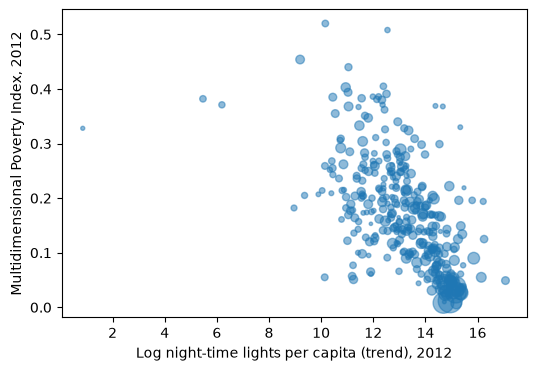

In [13]:
panel = geo.combine(["ntl", "pop"], scale="municipality", years=2012).merge(mpi, on=["geo_id", "year"])

ax = panel.plot.scatter(x="ln_t400NTLpc", y="sdg1_2_mpi", s=np.sqrt(panel["pop"]) / 4, alpha=0.5, figsize=(6, 4))
ax.set_xlabel("Log night-time lights per capita (trend), 2012"); ax.set_ylabel("Multidimensional Poverty Index, 2012")
print(f"correlation: {panel['ln_t400NTLpc'].corr(panel['sdg1_2_mpi']):.2f}")

## 4. Link your own table

Tables from reports and ministries identify units by name, spelled in many ways, or by INE code. `geo.link()` attaches the observatory's `geo_id`. It ignores accents, case, spaces and punctuation, and tries every name and code column in `geo.units()`.

The values below are **made up** for the demonstration; replace them with your own data.

In [14]:
mine = pd.DataFrame({
    "Departamento": ["LA PAZ", "Cochabamba", "Santa Cruz", "Potosi", "Chuquisaca", "La Paz"],
    "year":         [2020, 2020, 2020, 2020, 2020, 2021],
    "clinics":      [412, 301, 388, 266, 190, 420],          # illustrative values
})
mine = geo.link(mine, scale="department", on="Departamento")
mine

,geo_id,Departamento,year,clinics
0,BO-04,LA PAZ,2020,412
1,BO-02,Cochabamba,2020,301
2,BO-08,Santa Cruz,2020,388
3,BO-07,Potosi,2020,266
4,BO-01,Chuquisaca,2020,190
5,BO-04,La Paz,2021,420


In [15]:
geo.check(mine, scale="department")        # [] = a valid panel: known ids, one row per unit and year

[]

Municipal statistics from INE (and every DS4Bolivia table) carry codes. Link them by code: INE's 6-digit `ine_code`, the same code as a number (`mun_id`), or DS4Bolivia's `asdf_id`.

In [16]:
ine = pd.DataFrame({"codigo": [20101, 20105, 70101, 30101, 10101], "teachers": [9120, 6211, 11034, 5980, 2870]})
geo.link(ine, scale="municipality", on="codigo", key="mun_id").merge(
    geo.units("municipality")[["geo_id", "name"]], on="geo_id")

,geo_id,codigo,teachers,name
0,BO-04-17-04,20101,9120,La Paz
1,BO-04-17-02,20105,6211,El Alto
2,BO-08-01-05,70101,11034,Santa Cruz de la Sierra
3,BO-02-08-01,30101,5980,Cochabamba
4,BO-01-06-02,10101,2870,Sucre


A name shared by several municipalities, or a typo, stops with an explanation instead of silently linking the wrong unit:

In [17]:
for value in ["San Javier", "Cochabmba"]:
    try:
        geo.link(pd.DataFrame({"m": [value]}), scale="municipality", on="m", key="name")
    except ValueError as err:
        print(err, "\n")

1 row(s) of 'm' name several municipality units and were not linked: 'San Javier' (BO-03-01-01, BO-08-10-04). Link them by a code (key=...) instead. 

1 value(s) of 'm' match no municipality 'name': 'Cochabmba' (did you mean 'Cochabamba'?). Fix them, e.g. df['m'] = df['m'].replace({...}), or pass errors='warn'. 



## 5. Build a new indicator from a raster

`geo.zonal()` summarises any GeoTIFF (for example an export from Google Earth Engine, or a WorldPop population grid) over the units of a scale. As a self-contained example, we compute a raster of **distance to the nearest of Bolivia's three largest cities** (La Paz, Cochabamba and Santa Cruz de la Sierra, the "central axis"), a simple proxy of market access, and average it over municipalities.

In [18]:
import rasterio
from rasterio.transform import from_bounds

CITIES = {"La Paz": (-16.4955, -68.1336), "Cochabamba": (-17.3895, -66.1568), "Santa Cruz": (-17.7833, -63.1821)}

x0, y0, x1, y1 = geo.boundaries("country").total_bounds
nx, ny = 900, 1000                                             # about 1.5 km pixels
LON, LAT = np.meshgrid(np.linspace(x0, x1, nx), np.linspace(y1, y0, ny))

def haversine_km(lat, lon, lat0, lon0):
    lat, lon, lat0, lon0 = map(np.radians, (lat, lon, lat0, lon0))
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat) * np.sin((lon - lon0) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

km = np.min([haversine_km(LAT, LON, la, lo) for la, lo in CITIES.values()], axis=0)

with rasterio.open("distance_to_main_cities.tif", "w", driver="GTiff", width=nx, height=ny, count=1,
                   dtype="float32", crs="EPSG:4326", transform=from_bounds(x0, y0, x1, y1, nx, ny)) as dst:
    dst.write(km.astype("float32"), 1)

access = geo.zonal("distance_to_main_cities.tif", scale="municipality", stats=["mean", "max"], name="dist_axis_km")
access.head()

,geo_id,dist_axis_km_mean,dist_axis_km_max
0,BO-01-01-01,297.894443,328.066895
1,BO-01-01-02,265.082932,289.364838
2,BO-01-02-01,176.749234,197.361023
3,BO-01-03-01,325.186093,367.785889
4,BO-01-03-02,266.035842,325.332886


Is distance to the central axis associated with poverty? Join the new indicator to the poverty data:

correlation: 0.25


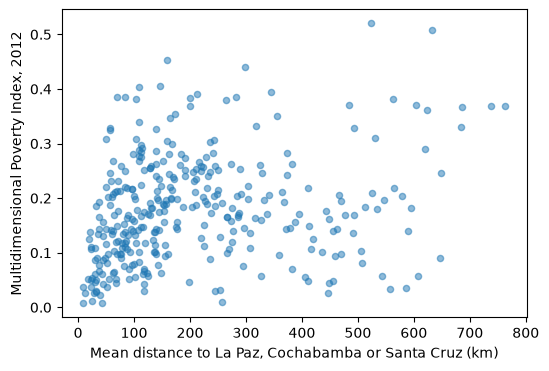

In [19]:
d = mpi.merge(access, on="geo_id")
ax = d.plot.scatter(x="dist_axis_km_mean", y="sdg1_2_mpi", alpha=0.5, figsize=(6, 4))
ax.set_xlabel("Mean distance to La Paz, Cochabamba or Santa Cruz (km)"); ax.set_ylabel("Multidimensional Poverty Index, 2012")
print(f"correlation: {d['dist_axis_km_mean'].corr(d['sdg1_2_mpi']):.2f}")

## 6. Interpolate to a grid and save

Grids, watersheds or a newer municipality map do not nest in the administrative hierarchy. `geo.overlay()` moves data onto them by area weights. Totals (`extensive`) are split by area; rates (`intensive`) are area-weighted means.

municipalities: 11,877,664  grid: 11,877,664


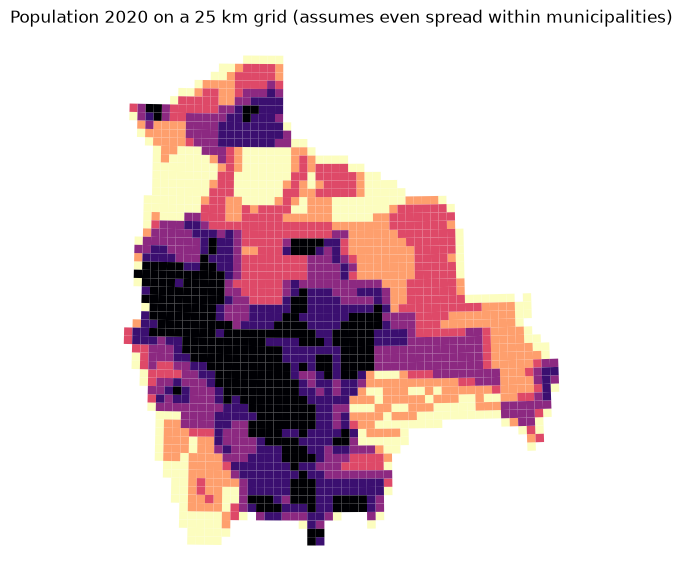

In [20]:
from shapely.geometry import box

crs = geo.config()["equal_area_crs"]                          # Albers equal-area fitted to Bolivia, metres
country = geo.boundaries("country").to_crs(crs)
gx0, gy0, gx1, gy1 = country.total_bounds
size = 25_000
cells = [box(x, y, x + size, y + size) for x in np.arange(gx0, gx1, size) for y in np.arange(gy0, gy1, size)]
grid = gpd.GeoDataFrame({"cell": [f"c{i}" for i in range(len(cells))]}, geometry=cells, crs=crs)
grid = grid[grid.intersects(country.geometry.iloc[0])].to_crs("EPSG:4326")

on_grid = geo.overlay(pop, grid, extensive=["pop"], id_col="cell")
print(f"municipalities: {pop['pop'].sum():,.0f}  grid: {on_grid['pop'].sum():,.0f}")

ax = grid.merge(on_grid.rename(columns={"geo_id": "cell"}), on="cell").plot(
    column="pop", cmap="magma_r", scheme="quantiles", k=6, figsize=(7, 7))
ax.set_axis_off(); ax.set_title("Population 2020 on a 25 km grid (assumes even spread within municipalities)");

Finally, save your indicator exactly like the published datasets: CSV, Parquet and a Frictionless datapackage describing every variable. It is then easy to share, reload or contribute to the observatory ([CONTRIBUTING_DATA.md](https://github.com/quarcs-lab/geo4bolivia/blob/main/CONTRIBUTING_DATA.md)).

In [21]:
access["year"] = 2024
geo.save(access[["geo_id", "year", "dist_axis_km_mean", "dist_axis_km_max"]], "market_access", scale="municipality",
         directory="my_data", title="Distance to the central axis",
         description="Mean and maximum straight-line distance from each municipality to the nearest of La Paz, Cochabamba and Santa Cruz de la Sierra.",
         variables={"dist_axis_km_mean": {"description": "Mean distance to the nearest main city", "unit": "km", "aggregation": "none"},
                    "dist_axis_km_max": {"description": "Maximum distance to the nearest main city", "unit": "km", "aggregation": "max"}})

wrote my_data/data/municipality/market_access.csv, my_data/data/municipality/market_access.parquet and my_data/metadata/market_access.datapackage.json


{'name': 'market_access',
 'title': 'Distance to the central axis',
 'description': 'Mean and maximum straight-line distance from each municipality to the nearest of La Paz, Cochabamba and Santa Cruz de la Sierra.',
 'version': '1.0.0',
 'licenses': [{'name': 'CC-BY-4.0'}],
 'sources': [],
 'geo:categories': [],
 'geo:notes': [],
 'resources': [{'name': 'market_access-municipality',
   'path': 'https://raw.githubusercontent.com/quarcs-lab/geo4bolivia/main/data/municipality/market_access.csv',
   'format': 'csv',
   'mediatype': 'text/csv',
   'encoding': 'utf-8',
   'geo:scale': 'municipality',
   'geo:period': [2024, 2024],
   'geo:path': 'data/municipality/market_access.csv',
   'geo:parquet': 'data/municipality/market_access.parquet',
   'schema': {'primaryKey': ['geo_id', 'year'],
    'fields': [{'name': 'geo_id',
      'type': 'string',
      'description': 'Municipality (339, GADM 4.1) ID',
      'geo:role': 'id',
      'constraints': {'required': True,
       'pattern': '^BO-\\d

## Next steps

- Explore poverty and lights spatially: [`esda.ipynb`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda.ipynb)
- Predict poverty from satellite embeddings: [`embeddings_mpi_ml.ipynb`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/embeddings_mpi_ml.ipynb)
- The full guide: [how the data infrastructure works](https://github.com/quarcs-lab/geo4bolivia/blob/main/docs/data-infrastructure.md)
- Every function has help: `help(geo.link)`